# Oxford-IIIT Pet: Woher kommt die Unsicherheit?

- **Voraussetzungen:** [Baseline 0](dan_02-0_oxford-pets-vgg16-baseline.ipynb),
  [probly 1](dan_02-1_oxford-pets-probly.ipynb) und
  [shapiq 2](dan_02-2_oxford-pets-shapiq.ipynb) sind ausgeführt.
- Wir verbinden die gespeicherten probly-Köpfe mit den bereits berechneten Bildspielen.
  **Kein Training und kein weiterer VGG-Vorwärtslauf** finden hier statt.
- Dieselben Koalitionen erklären nun Rassenwahrscheinlichkeit **P**, totale **TU**,
  aleatorische **AU** und epistemische **EU** Unsicherheit. Definitionen und Grenzen
  der Zerlegung stehen in Notebook 1; die Maskierungsspiele und k-SII in Notebook 2.
- Fragen: Welche Regionen helfen bei der Vorhersage, welche verändern Unsicherheit?
  Bleiben die Aussagen bei anderer Maskierung und weniger Trainingsdaten stabil?
  Können die gemeinsam vortrainierten Köpfe Fehler mit niedriger EU übersehen?
- Die 37 vorab über Bild-IDs ausgewählten Fälle sind eine kleine, rassenbalancierte
  Diagnosekohorte. Die Fallgrafiken zeigen gezielt ausgewählte Mitglieder dieser Kohorte;
  sie erhalten in den aggregierten Kennzahlen kein zusätzliches Gewicht.

In [1]:
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import shapiq
import torch
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import spearmanr

from probly.quantification import quantify
from probly.representer import representer
from probly.transformation import ensemble

REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "probly").is_dir()
)
NOTEBOOK_DIR = REPO_ROOT / "experiments" / "group-d_experiments"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from dan_02_common import (
    ARTIFACT_DIR, load_baseline, load_selection, load_torch, make_head,
    save_torch, state_fingerprint, versions,
)

torch.set_num_threads(4)
bundle = load_baseline()
selection = load_selection()
baseline_fingerprint = state_fingerprint(bundle["checkpoint"]["head_state_dict"])
class_names = list(bundle["checkpoint"]["classes"])
models_artifact = load_torch(
    ARTIFACT_DIR / "probly" / "models.pt",
    prerequisite="dan_02-1_oxford-pets-probly.ipynb",
)
index_path = ARTIFACT_DIR / "shapiq" / "index.json"
if not index_path.is_file():
    raise FileNotFoundError("Zuerst dan_02-2_oxford-pets-shapiq.ipynb ausführen.")
shapiq_index = json.loads(index_path.read_text())
if not shapiq_index.get("complete", False):
    raise RuntimeError("Der shapiq-Export ist noch unvollständig. Notebook 2 zuerst vollständig ausführen.")
assert models_artifact["baseline_fingerprint"] == baseline_fingerprint
assert shapiq_index["baseline_fingerprint"] == baseline_fingerprint
assert models_artifact["classes"] == class_names
assert len(shapiq_index["cohort_ids"]) == len(set(shapiq_index["cohort_ids"])) == 37
assert shapiq_index["cohort_ids"] == selection["explanation_ids"]
assert bundle["test"]["labels"][selection["explanation_indices"]].unique().numel() == 37
OUTPUT_DIR = ARTIFACT_DIR / "combined"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SCORES = ("P", "TU", "AU", "EU")
GROUP_NAMES = ("Tier", "Hintergrund", "Rand / unklar")
FILLS = ("blur", "mean")
installed_versions = versions()
print("Geladene Köpfe und Maskenmerkmale; Rechengerät der Köpfe: CPU / float64.")
print("Versionen:", installed_versions)

Geladene Köpfe und Maskenmerkmale; Rechengerät der Köpfe: CPU / float64.
Versionen: {'torch': '2.10.0', 'torchvision': '0.25.0', 'numpy': '2.5.3', 'Pillow': '12.2.0', 'probly': '0.1.dev661+g6508e3195', 'shapiq': '1.8.0', 'scikit-learn': '1.8.0'}


## 1. Gespeicherte Köpfe durch die öffentliche probly-Pipeline

- Ein Ensemble enthält drei gespeicherte Köpfe. `reset_params=False` verhindert eine
  Neuinitialisierung; anschließend laden wir ausdrücklich jeden unterschiedlichen Zustand.
- `representer`, `sample_mean()` und `quantify` übernehmen die semantischen Modell-
  und Klassenachsen. Wir raten keine Position der Ensembleachse.
- Float64 auf der CPU hält die Identitätsprüfungen auch für sehr kleine EU stabil.
  VGG-Merkmale bleiben die gespeicherten Float32-Werte.
- Die Zielrasse jedes Bildes ist die **vollständige Baseline-Vorhersage** aus Notebook 0.
  Sie bleibt über Koalitionen und Datenmengen fest. P bedeutet deshalb überall denselben Score.

In [2]:
model_records = {"full": models_artifact["full"], **models_artifact["scarce"]}
expected_scarce = {f"k{k}_s{seed}" for k in (5, 20) for seed in (10, 11, 12)}
assert set(model_records) == {"full", *expected_scarce}


def restore_ensemble(record: dict):
    """Restore typed, distinct saved heads without training or resetting parameters."""
    base = make_head(models_artifact["config"], n_classes=len(class_names), dtype=torch.float64)
    model = ensemble(base, num_members=3, reset_params=False, predictor_type="logit_classifier")
    assert len(record["states"]) == len(model) == 3
    for member, state in zip(model, record["states"], strict=True):
        member.load_state_dict(state)
    return model.to(dtype=torch.float64, device="cpu").eval()


ensembles = {name: restore_ensemble(record) for name, record in model_records.items()}
model_fingerprints = {
    name: hashlib.sha256("".join(state_fingerprint(state) for state in record["states"]).encode()).hexdigest()
    for name, record in model_records.items()
}


def probly_scores(model, features: torch.Tensor, target_class: int) -> dict:
    """Return mean probabilities and probly's three scalar uncertainty games."""
    probability_batches = []
    uncertainty_batches = {name: [] for name in ("TU", "AU", "EU")}
    with torch.no_grad():
        for batch in features.split(256):
            representation = representer(model).represent(batch.to(dtype=torch.float64, device="cpu"))
            decomposition = quantify(representation)
            probability_batches.append(representation.sample_mean().probabilities.detach().cpu())
            for short, long_name in (("TU", "total"), ("AU", "aleatoric"), ("EU", "epistemic")):
                uncertainty_batches[short].append(
                    torch.as_tensor(getattr(decomposition, long_name)).detach().cpu()
                )
    probabilities = torch.cat(probability_batches)
    scores = {name: torch.cat(batches) for name, batches in uncertainty_batches.items()}
    scores["P"] = probabilities[:, target_class]
    assert probabilities.shape == (len(features), len(class_names))
    assert all(torch.isfinite(value).all() for value in scores.values())
    torch.testing.assert_close(probabilities.sum(1), torch.ones(len(features), dtype=torch.float64))
    torch.testing.assert_close(scores["TU"], scores["AU"] + scores["EU"], atol=1e-11, rtol=1e-10)
    assert scores["EU"].min() > -1e-10
    return {"scores": scores, "probabilities": probabilities}


# A zero-EU sanity control uses identical heads, not independently fitted models.
identical = restore_ensemble({"states": [model_records["full"]["states"][0]] * 3})
identical_control = probly_scores(identical, bundle["test"]["features"][:8], target_class=0)
assert identical_control["scores"]["EU"].abs().max() < 1e-11
print("Identische Köpfe: EU ≈ 0; gespeicherte Ensemblezustände wiederhergestellt.")

Identische Köpfe: EU ≈ 0; gespeicherte Ensemblezustände wiederhergestellt.


## 2. Exakte Spiele wiederverwenden und ihre Zerlegung prüfen

- Die booleschen Koalitionen und Merkmale stammen ausschließlich aus Notebook 2.
  Die Bitreihenfolge wird geprüft; die leere und vollständige Koalition bleiben sichtbar.
- Für jedes der vier Spiele berechnet der öffentliche `shapiq.ExactComputer`
  Shapley-Werte und k-SII bis Ordnung zwei aus einer reinen Tabellenfunktion.
- **TU = AU + EU** muss für Spielwerte, Shapley-Werte und k-SII gelten.
  Das folgt aus Linearität und ist eine technische Konsistenzprüfung, kein empirischer Befund.
- Alle 37 Bilder werden mit beiden Füllungen als Raster- und semantische Spiele untersucht.
  Für Datenknappheit verwenden wir dieselben Merkmale mit allen sechs knappen Ensembles.

In [3]:
def exact_scores(values: torch.Tensor, coalitions: torch.Tensor) -> dict:
    """Explain a raw scalar lookup game with public exact Shapley and k-SII APIs."""
    table = values.numpy().astype(np.float64, copy=False)
    n_players = coalitions.shape[1]
    binary_weights = 1 << np.arange(n_players, dtype=np.int64)
    indices = coalitions.numpy().astype(np.int64) @ binary_weights
    assert np.array_equal(indices, np.arange(2 ** n_players))

    def game(query: np.ndarray) -> np.ndarray:
        return table[np.asarray(query, dtype=np.int64) @ binary_weights]

    computer = shapiq.ExactComputer(game, n_players=n_players)
    sv = computer(index="SV", order=1)
    ksii = computer(index="k-SII", order=min(2, n_players))
    singles = np.array([ksii[(i,)] for i in range(n_players)])
    pairs = np.zeros((n_players, n_players), dtype=np.float64)
    for i in range(n_players):
        for j in range(i + 1, n_players):
            pairs[i, j] = pairs[j, i] = ksii[(i, j)]
    result = {
        "values": values.clone(),
        "sv": torch.tensor([sv[(i,)] for i in range(n_players)], dtype=torch.float64),
        "ksii_single": torch.from_numpy(singles),
        "ksii_pairs": torch.from_numpy(pairs),
        "baseline": float(sv.baseline_value),
    }
    assert np.isclose(result["baseline"], table[0], atol=1e-10)
    assert np.isclose(result["baseline"] + result["sv"].sum().item(), table[-1], atol=1e-9)
    assert np.isclose(
        ksii.baseline_value + singles.sum() + np.triu(pairs, 1).sum(), table[-1], atol=1e-9
    )
    return result


def validate_explanations(result: dict) -> None:
    """Check finite exact results, efficiency, and uncertainty linearity."""
    games = result["games"]
    for field in ("values", "sv", "ksii_single", "ksii_pairs"):
        for score in SCORES:
            assert torch.isfinite(games[score][field]).all()
        torch.testing.assert_close(
            games["TU"][field], games["AU"][field] + games["EU"][field],
            atol=1e-9, rtol=1e-8,
        )
    assert abs(games["TU"]["baseline"] - games["AU"]["baseline"] - games["EU"]["baseline"]) < 1e-10


def combined_result(source_record: dict, model_name: str = "full") -> dict:
    """Load or derive exact ensemble games from an existing masked-feature artifact."""
    source_path = ARTIFACT_DIR / source_record["path"]
    source = load_torch(source_path, prerequisite="dan_02-2_oxford-pets-shapiq.ipynb")
    manifest = {
        "schema_version": 1,
        "source_manifest": source["manifest"],
        "source_path": source_record["path"],
        "baseline_fingerprint": baseline_fingerprint,
        "model_fingerprint": model_fingerprints[model_name],
        "versions": {name: installed_versions[name] for name in ("probly", "shapiq", "torch")},
        "arithmetic": "CPU float64; public probly representer/quantify",
        "target_class": int(source["target_class"]),
    }
    key = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:24]
    output_path = OUTPUT_DIR / f"{key}.pt"
    if output_path.is_file():
        result = load_torch(output_path)
        assert result["manifest"] == manifest
        validate_explanations(result)
        return result
    predictions = probly_scores(ensembles[model_name], source["features"], int(source["target_class"]))
    result = {
        "manifest": manifest,
        "image_id": source["image_id"],
        "target_class": int(source["target_class"]),
        "true_class": int(source["true_class"]),
        "probabilities": predictions["probabilities"],
        "games": {
            name: exact_scores(predictions["scores"][name], source["coalitions"])
            for name in SCORES
        },
    }
    validate_explanations(result)
    save_torch(output_path, result)
    return result


cohort_ids = set(shapiq_index["cohort_ids"])
main_records = [
    record for record in shapiq_index["records"]
    if record["image_id"] in cohort_ids and record["regions_kind"] in ("grid", "semantic")
]
for kind in ("grid", "semantic"):
    for fill in FILLS:
        subset = [record for record in main_records if record["regions_kind"] == kind and record["fill"] == fill]
        assert len(subset) == 37 and {record["image_id"] for record in subset} == cohort_ids

full_results = {}
scarce_results = {}
for counter, record in enumerate(main_records, start=1):
    record_key = (record["image_id"], record["regions_kind"], record["fill"])
    full_results[record_key] = combined_result(record)
    for model_name in sorted(expected_scarce):
        scarce_results[(record_key, model_name)] = combined_result(record, model_name)
    if counter % 10 == 0 or counter == len(main_records):
        print(f"{counter}/{len(main_records)} gemeinsame Bildspiele für alle Datenmengen geprüft.")
print("Alle Spielwerte, SV und k-SII erfüllen TU = AU + EU sowie die Effizienzprüfung.")

10/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


20/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


30/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


40/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


50/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


60/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


... (4 outputs left out)

110/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


120/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


130/148 gemeinsame Bildspiele für alle Datenmengen geprüft.


140/148 gemeinsame Bildspiele für alle Datenmengen geprüft.
148/148 gemeinsame Bildspiele für alle Datenmengen geprüft.
Alle Spielwerte, SV und k-SII erfüllen TU = AU + EU sowie die Effizienzprüfung.


## 3. Wahrscheinlichkeit und Unsicherheit im selben Bild

- Wir verwenden die vorab in Notebook 0 definierten Diagnosefälle; ihre Auswahlrollen
  sind im Titel sichtbar. Sie werden nicht als repräsentative Stichprobe ausgegeben.
- Rot bedeutet einen positiven, Blau einen negativen Beitrag relativ zum jeweiligen Spiel.
  **Positives EU-Attribut erhöht Unsicherheit**, ein negatives senkt sie.
- P hat Wahrscheinlichkeitspunkte, die drei Unsicherheitskarten haben Nats als Einheit.
  Je Score gilt über alle Diagnosefälle dieselbe symmetrische Farbskala; auch die
  EU-Interaktionsskala bleibt zwischen Fällen gleich. Zwischen verschiedenen Scores
  können ähnlich aussehende Farben andere Beträge bedeuten.
- Die letzte Grafik eines Falls zeigt paarweise EU-Interaktionen. Rasterregionen sind
  zusammengesetzte Eingriffe; eine Interaktion ist kein Beweis einer biologischen Ursache.

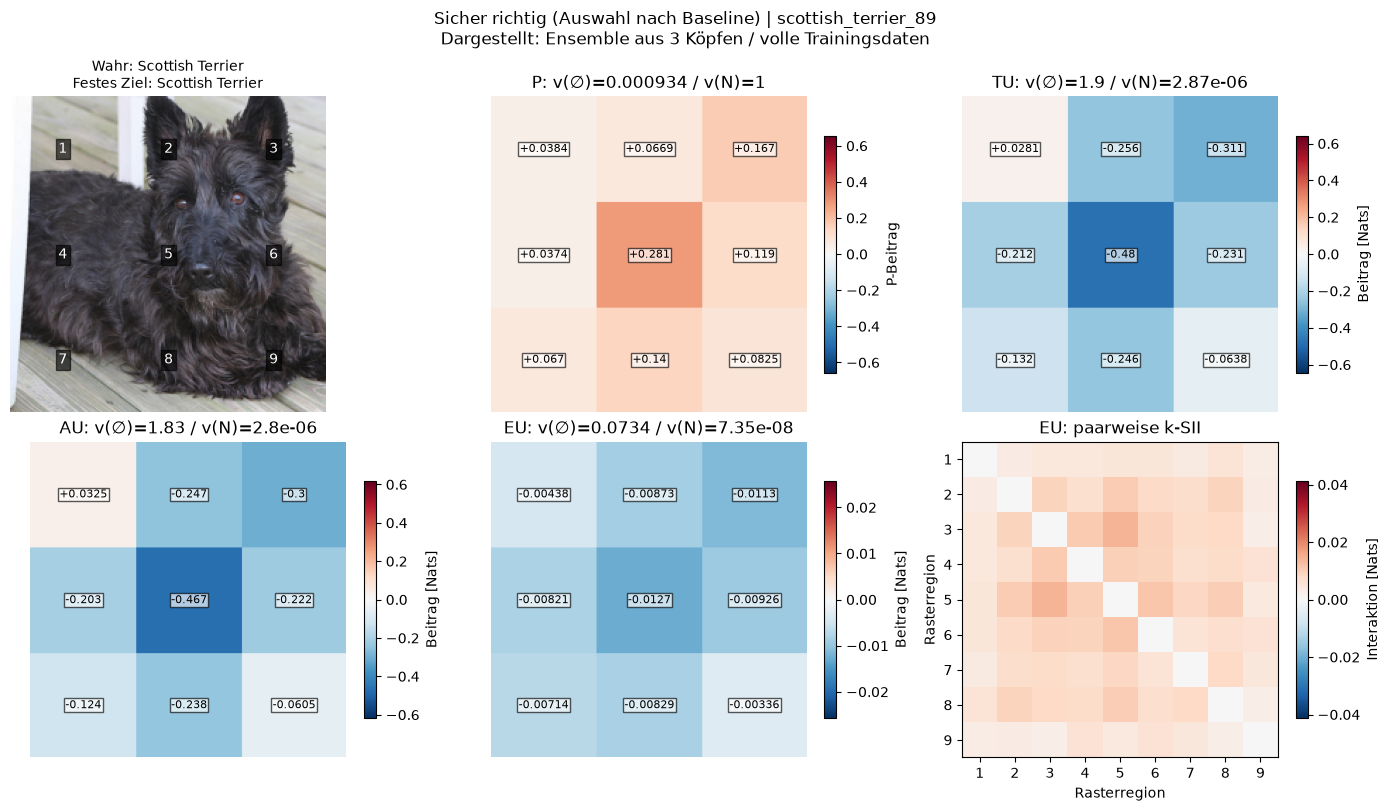

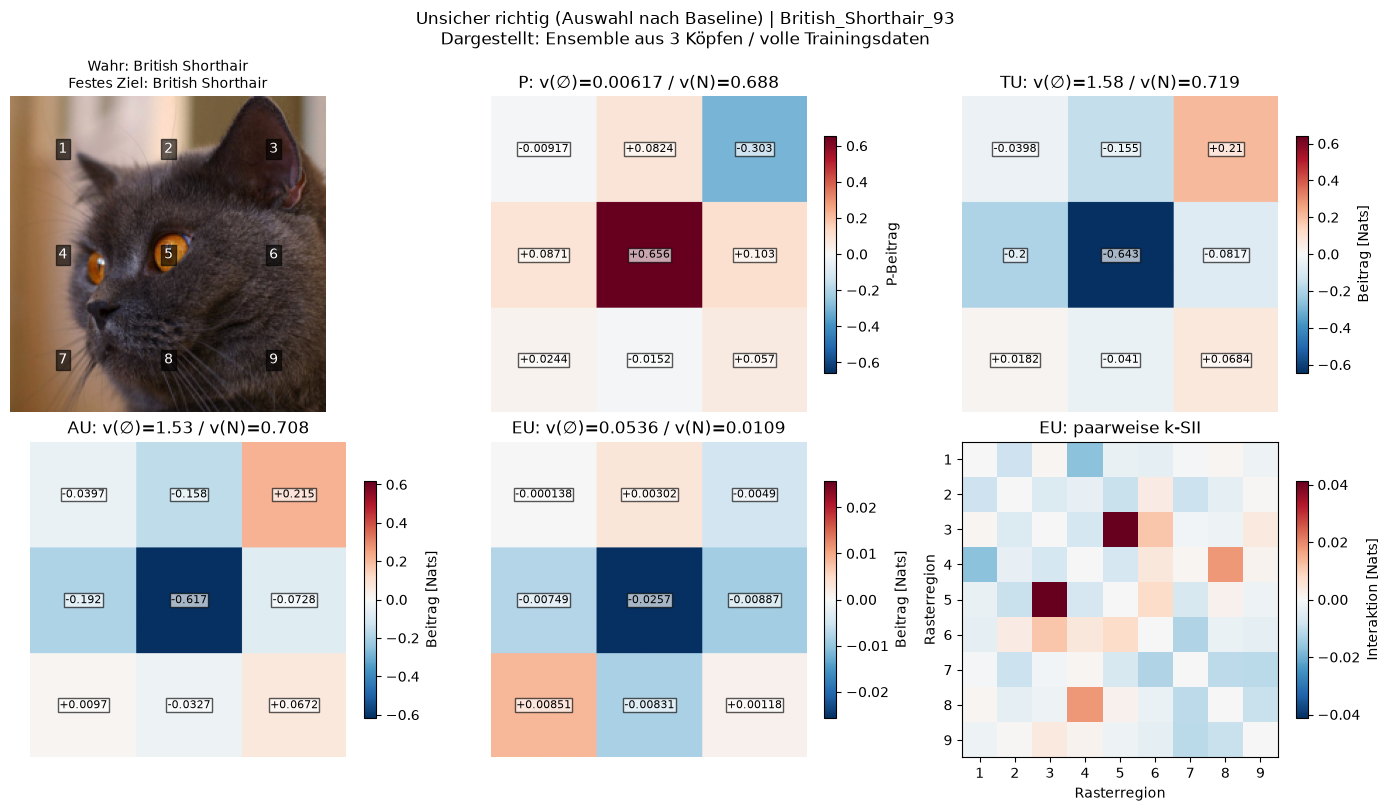

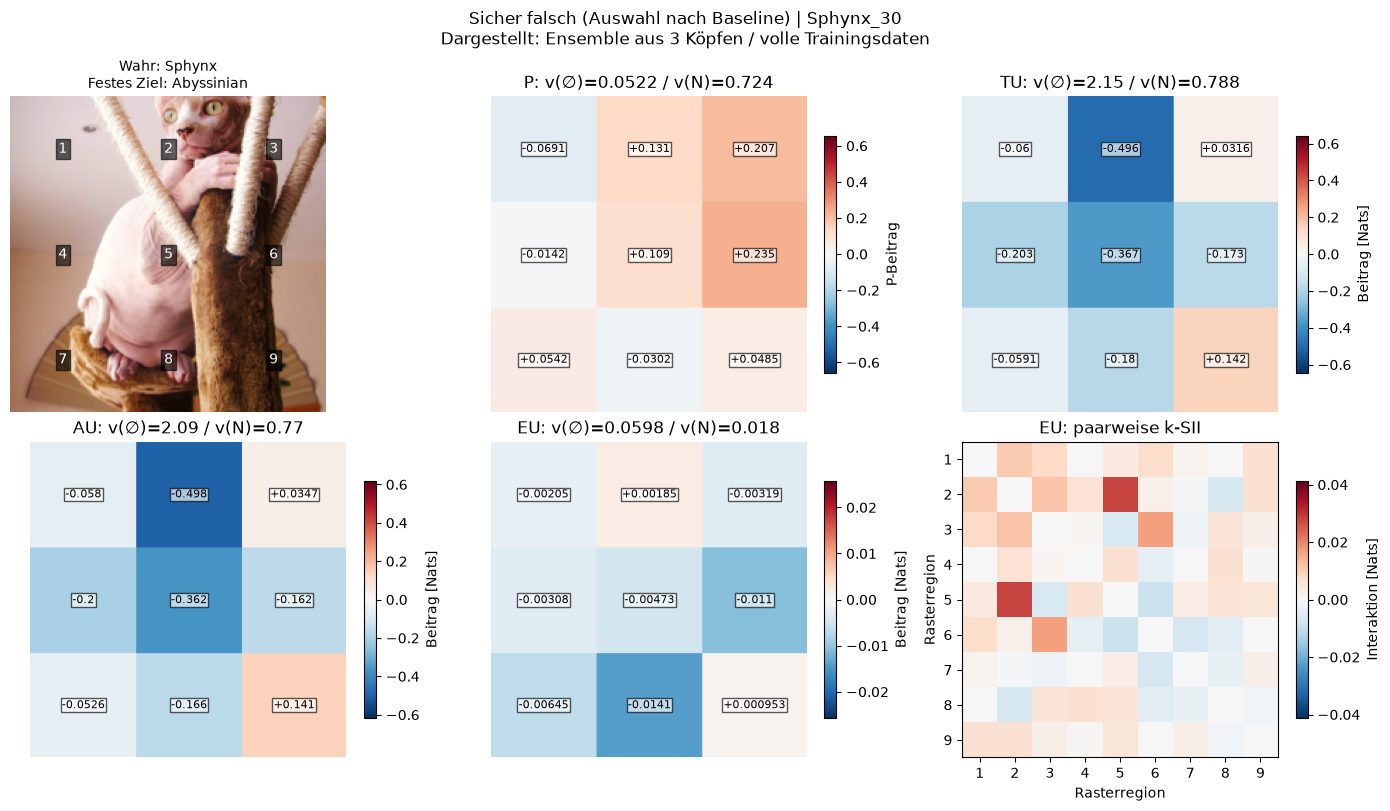

In [4]:
def signed_norm(values: np.ndarray, limit: float | None = None) -> TwoSlopeNorm:
    """Use a symmetric nondegenerate color scale, including near-zero results."""
    limit = max(float(np.abs(values).max()) if limit is None else float(limit), 1e-12)
    return TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)


record_lookup = {
    (record["image_id"], record["regions_kind"], record["fill"]): record
    for record in shapiq_index["records"]
}
diagnostics = shapiq_index["diagnostic_cases"]
diagnostic_results = [full_results[(case["image_id"], "grid", "blur")] for case in diagnostics]
diagnostic_sv_limits = {
    score: max(result["games"][score]["sv"].abs().max().item() for result in diagnostic_results)
    for score in SCORES
}
diagnostic_pair_limit = max(
    result["games"]["EU"]["ksii_pairs"].abs().max().item() for result in diagnostic_results
)
for case in diagnostics:
    key = (case["image_id"], "grid", "blur")
    record = record_lookup[key]
    source = load_torch(ARTIFACT_DIR / record["path"])
    result = full_results[key] if key in full_results else combined_result(record)
    regions = source["regions"].numpy()
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
    axes[0, 0].imshow(source["crop"].numpy())
    for region in range(int(regions.max()) + 1):
        rows, cols = np.where(regions == region)
        axes[0, 0].text(cols.mean(), rows.mean(), str(region + 1), ha="center", va="center",
                        color="white", bbox={"facecolor": "black", "alpha": 0.6, "pad": 2})
    axes[0, 0].set_title(f"Wahr: {class_names[source['true_class']]}\nFestes Ziel: {class_names[source['target_class']]}", fontsize=10)
    axes[0, 0].axis("off")
    for score, ax in zip(SCORES, (axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]), strict=True):
        contributions = result["games"][score]["sv"].numpy()
        shown = ax.imshow(contributions[regions], cmap="RdBu_r",
                          norm=signed_norm(contributions, diagnostic_sv_limits[score]))
        for region, contribution in enumerate(contributions):
            rows, cols = np.where(regions == region)
            ax.text(cols.mean(), rows.mean(), f"{contribution:+.3g}", ha="center", va="center", fontsize=8,
                    bbox={"facecolor": "white", "alpha": 0.65, "pad": 1})
        value = result["games"][score]["values"][-1].item()
        baseline = result["games"][score]["baseline"]
        ax.set_title(f"{score}: v(∅)={baseline:.3g} / v(N)={value:.3g}")
        ax.axis("off")
        fig.colorbar(shown, ax=ax, shrink=0.75, label="P-Beitrag" if score == "P" else "Beitrag [Nats]")
    pairs = result["games"]["EU"]["ksii_pairs"].numpy()
    shown = axes[1, 2].imshow(pairs, cmap="RdBu_r", norm=signed_norm(pairs, diagnostic_pair_limit))
    axes[1, 2].set(xticks=np.arange(9), yticks=np.arange(9), xticklabels=np.arange(1, 10), yticklabels=np.arange(1, 10),
                   title="EU: paarweise k-SII", xlabel="Rasterregion", ylabel="Rasterregion")
    fig.colorbar(shown, ax=axes[1, 2], shrink=0.75, label="Interaktion [Nats]")
    fig.suptitle(
        f"{case['role']} (Auswahl nach Baseline) | {case['image_id']}\n"
        "Dargestellt: Ensemble aus 3 Köpfen / volle Trainingsdaten", fontsize=12,
    )
    plt.show()

## 4. Liegen Beiträge auf dem Tier oder auf dem Hintergrund?

- Für jede Rasterregion messen wir den tatsächlichen Flächenanteil von Tier, Hintergrund
  und unklarem Rand nach dem gemeinsamen Bildausschnitt.
- Die **absolute Attributionsmasse** wird anteilig auf diese drei Gruppen verteilt und durch
  die gesamte absolute Masse des Spiels geteilt. Die Gruppen summieren sich dadurch zu eins.
- Wir ziehen den Bildflächenanteil ab: Null bedeutet die Verteilung eines räumlich gleichmäßig
  verteilten Betrags. Positive Werte zeigen überproportionale Attributionsmasse.
- Das ist eine grobe Lokalisierungsdiagnose, keine Annotation der wahren Modellbegründung.
  Ein größerer Hintergrundbeitrag kann statistisch nützlich sein; Trimaps bewerten keine Kausalität.
- Die direkten semantischen Spiele greifen stattdessen jeweils auf die ganze Gruppe zu.
  Ihre Spieler und Gegenfakten unterscheiden sich vom Raster; sie werden separat gezeigt.

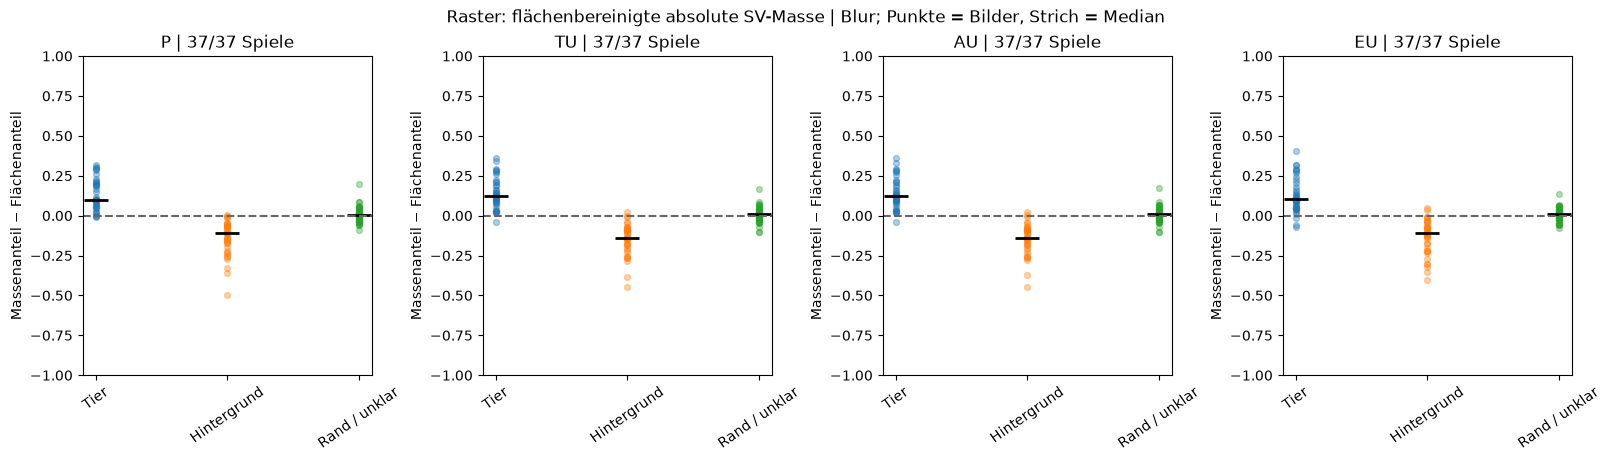

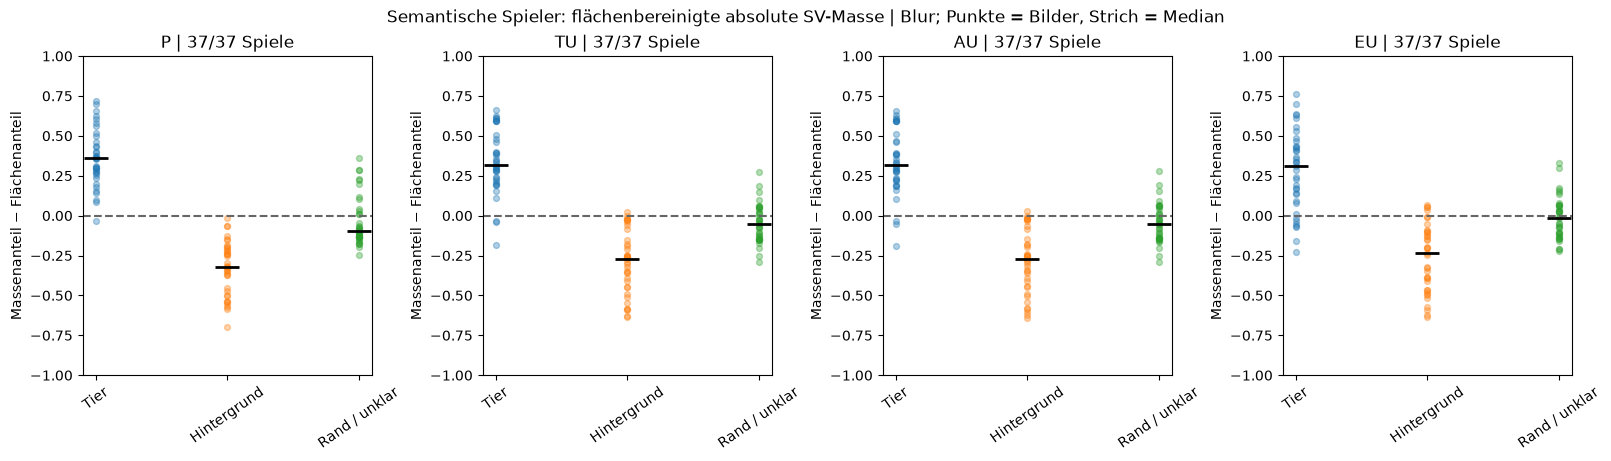

Mittlere Flächenanteile Tier/Hintergrund/Rand: [0.449 0.39  0.161]


In [5]:
def geometry(source: dict) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return per-player area, raw-trimap group fractions, and image group area."""
    regions, trimap = source["regions"].numpy(), source["trimap"].numpy().squeeze()
    assert regions.shape == trimap.shape
    assert set(np.unique(trimap)).issubset({1, 2, 3})
    n_players = source["coalitions"].shape[1]
    areas = np.array([(regions == player).mean() for player in range(n_players)])
    assert (areas > 0).all() and np.isclose(areas.sum(), 1)
    fractions = np.array([
        [(trimap[regions == player] == group).mean() for group in (1, 2, 3)]
        for player in range(n_players)
    ])
    image_area = np.array([(trimap == group).mean() for group in (1, 2, 3)])
    np.testing.assert_allclose(areas @ fractions, image_area, atol=1e-12)
    return areas, fractions, image_area


localization = {kind: {score: [] for score in SCORES} for kind in ("grid", "semantic")}
localization_area = {kind: [] for kind in ("grid", "semantic")}
for record in main_records:
    if record["fill"] != "blur":
        continue
    kind = record["regions_kind"]
    source = load_torch(ARTIFACT_DIR / record["path"])
    _, fractions, image_area = geometry(source)
    result = full_results[(record["image_id"], kind, "blur")]
    localization_area[kind].append(image_area)
    for score in SCORES:
        mass = result["games"][score]["sv"].abs().numpy()
        if mass.sum() < 1e-10:
            enrichment = np.full(3, np.nan)
        else:
            allocation = mass @ fractions / mass.sum()
            np.testing.assert_allclose(allocation.sum(), 1, atol=1e-10)
            enrichment = allocation - image_area
        localization[kind][score].append(enrichment)

for kind, title in (("grid", "Raster: flächenbereinigte absolute SV-Masse"),
                    ("semantic", "Semantische Spieler: flächenbereinigte absolute SV-Masse")):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), layout="constrained")
    for ax, score in zip(axes, SCORES, strict=True):
        values = np.asarray(localization[kind][score])
        for group in range(3):
            valid = values[:, group][np.isfinite(values[:, group])]
            ax.scatter(np.full(len(valid), group), valid, color=f"C{group}", alpha=0.35, s=18)
            if len(valid):
                ax.scatter(group, np.median(valid), color="black", marker="_", s=300, linewidths=2)
        ax.axhline(0, color="0.4", linestyle="--")
        ax.set(xticks=np.arange(3), xticklabels=GROUP_NAMES, title=f"{score} | {np.isfinite(values[:, 0]).sum()}/37 Spiele",
               ylabel="Massenanteil − Flächenanteil", ylim=(-1, 1))
        ax.tick_params(axis="x", labelrotation=35)
    fig.suptitle(title + " | Blur; Punkte = Bilder, Strich = Median", fontsize=12)
    plt.show()
print("Mittlere Flächenanteile Tier/Hintergrund/Rand:", np.round(np.mean(localization_area["grid"], axis=0), 3))

## 5. Regionale Interaktionen und Empfindlichkeit gegenüber dem Ersatzbild

- Die Interaktionsgrafik mittelt **absolute** paarweise semantische k-SII über alle 37 Bilder.
  Sie beschreibt Stärke, nicht deren Vorzeichen. Einzelne positive und negative Wechselwirkungen
  sind in den Fallgrafiken sichtbar. Je Score teilen Blur und Mittelwert dieselbe Farbskala.
- Referenzsensitivität vergleichen wir für dieselben Bilder und Regionen: Rangkorrelation
  der SV und Vorzeichenübereinstimmung, wenn beide Beiträge größer als `1e-8` sind.
- Konstante Karten haben keine Rangkorrelation; völlig kleine Beiträge keine Vorzeichenquote.
  Solche Werte bleiben fehlend und werden mit ihrer Anzahl ausgewiesen.
- Hohe Sensitivität bedeutet: Die inhaltliche Aussage hängt stark vom gewählten Gegenfaktum ab.

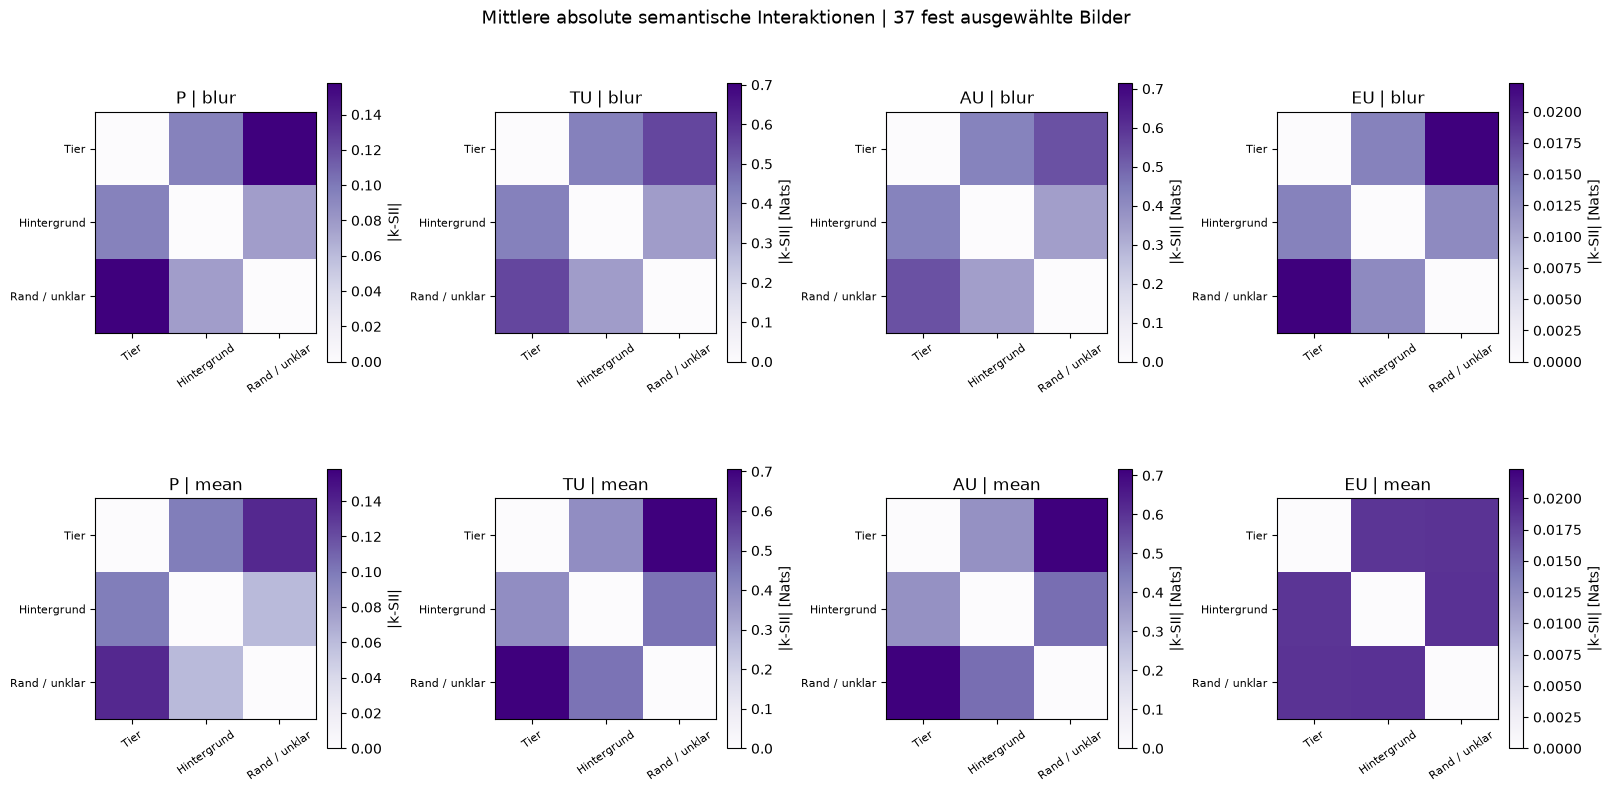

rho / P: 37/37 definiert; Median 0.883
rho / TU: 37/37 definiert; Median 0.817
rho / AU: 37/37 definiert; Median 0.817
rho / EU: 37/37 definiert; Median 0.633
sign / P: 37/37 definiert; Median 0.889
sign / TU: 37/37 definiert; Median 0.778
sign / AU: 37/37 definiert; Median 0.778
sign / EU: 37/37 definiert; Median 0.667


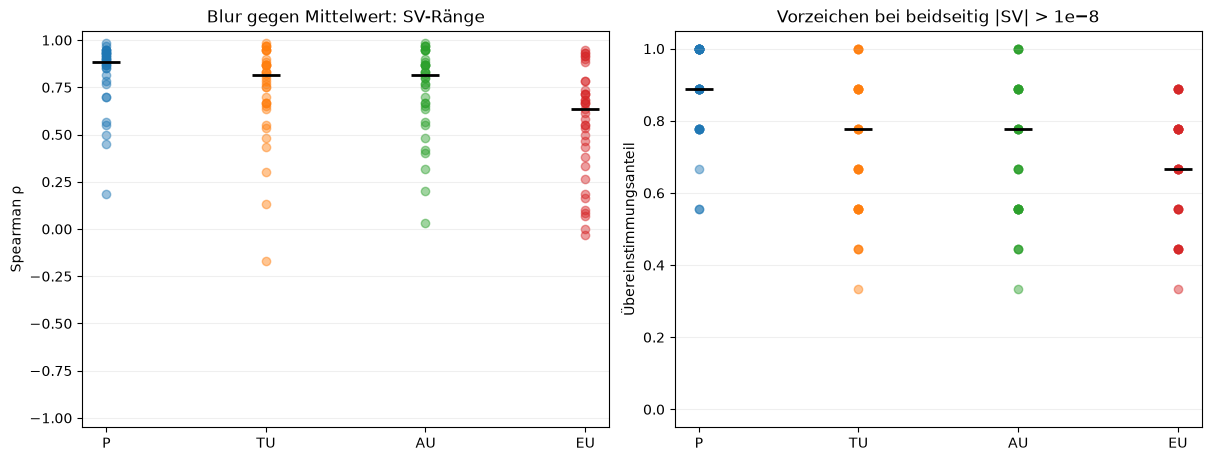

In [6]:
semantic_interaction_averages = {}
for fill in FILLS:
    for score in SCORES:
        matrices = []
        for image_id in shapiq_index["cohort_ids"]:
            key = (image_id, "semantic", fill)
            source = load_torch(ARTIFACT_DIR / record_lookup[key]["path"])
            _, fractions, _ = geometry(source)
            pairs = full_results[key]["games"][score]["ksii_pairs"].abs().numpy()
            # Actual present semantic players map to raw trimap groups; absent groups contribute zero.
            matrices.append(fractions.T @ pairs @ fractions)
        semantic_interaction_averages[(fill, score)] = np.mean(matrices, axis=0)
semantic_interaction_limits = {
    score: max(float(semantic_interaction_averages[(fill, score)].max()) for fill in FILLS)
    for score in SCORES
}
fig, axes = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
for row, fill in enumerate(FILLS):
    for col, score in enumerate(SCORES):
        average = semantic_interaction_averages[(fill, score)]
        ax = axes[row, col]
        shown = ax.imshow(average, cmap="Purples", vmin=0,
                          vmax=max(semantic_interaction_limits[score], 1e-12))
        ax.set(xticks=np.arange(3), yticks=np.arange(3), xticklabels=GROUP_NAMES, yticklabels=GROUP_NAMES,
               title=f"{score} | {fill}")
        ax.tick_params(axis="x", labelrotation=35, labelsize=8)
        ax.tick_params(axis="y", labelsize=8)
        fig.colorbar(shown, ax=ax, shrink=0.75, label="|k-SII|" + ("" if score == "P" else " [Nats]"))
fig.suptitle("Mittlere absolute semantische Interaktionen | 37 fest ausgewählte Bilder", fontsize=13)
plt.show()

reference_sensitivity = {score: {"rho": [], "sign": []} for score in SCORES}
for image_id in shapiq_index["cohort_ids"]:
    for score in SCORES:
        blur = full_results[(image_id, "grid", "blur")]["games"][score]["sv"].numpy()
        mean = full_results[(image_id, "grid", "mean")]["games"][score]["sv"].numpy()
        rho = float(spearmanr(blur, mean).statistic) if min(np.ptp(blur), np.ptp(mean)) > 1e-12 else np.nan
        strong = (np.abs(blur) > 1e-8) & (np.abs(mean) > 1e-8)
        agreement = float((np.sign(blur[strong]) == np.sign(mean[strong])).mean()) if strong.any() else np.nan
        reference_sensitivity[score]["rho"].append(rho)
        reference_sensitivity[score]["sign"].append(agreement)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, field, title, bounds in ((axes[0], "rho", "Blur gegen Mittelwert: SV-Ränge", (-1.05, 1.05)),
                                (axes[1], "sign", "Vorzeichen bei beidseitig |SV| > 1e−8", (-0.05, 1.05))):
    for index, score in enumerate(SCORES):
        values = np.asarray(reference_sensitivity[score][field])
        valid = values[np.isfinite(values)]
        ax.scatter(np.full(len(valid), index), valid, color=f"C{index}", alpha=0.45)
        if len(valid):
            ax.scatter(index, np.median(valid), marker="_", s=400, color="black", linewidths=2)
        print(f"{field} / {score}: {len(valid)}/37 definiert; Median {np.median(valid) if len(valid) else np.nan:.3f}")
    ax.set(xticks=np.arange(4), xticklabels=SCORES, title=title, ylim=bounds,
           ylabel="Spearman ρ" if field == "rho" else "Übereinstimmungsanteil")
    ax.grid(axis="y", alpha=0.2)
plt.show()

## 6. Weniger Daten: Werden Niveau, Karten und Interaktionen anders?

- Verglichen werden die gespeicherten Ensembles mit **5, 20 und allen Trainingsbildern
  pro Rasse**. Für 5 und 20 gibt es drei verschachtelte Teilmengenauswahlen und je drei Köpfe.
  Der Validierungssplit und die Modellwahlregel bleiben gleich; hier wird nichts nachtrainiert.
- Linien verbinden dasselbe Bild. Für die knappen Varianten zeigen sie den Mittelwert
  über die drei Teilmengenauswahlen. Die zusätzlichen Tabellen halten deren Streuung sichtbar.
- `Σ|SV_EU|` und `Σ|k-SII_EU|` über ungeordnete Paare messen die Stärke des jeweiligen
  Spiels, keine Unsicherheit pro Pixel. Die Kartenänderung ist der rohe L1-Abstand zur Vollvariante.
- Wir erwarten keine zwangsläufige Monotonie: Mehrere Köpfe mit demselben vortrainierten
  Backbone können auch bei wenig Daten dieselben Fehler machen.

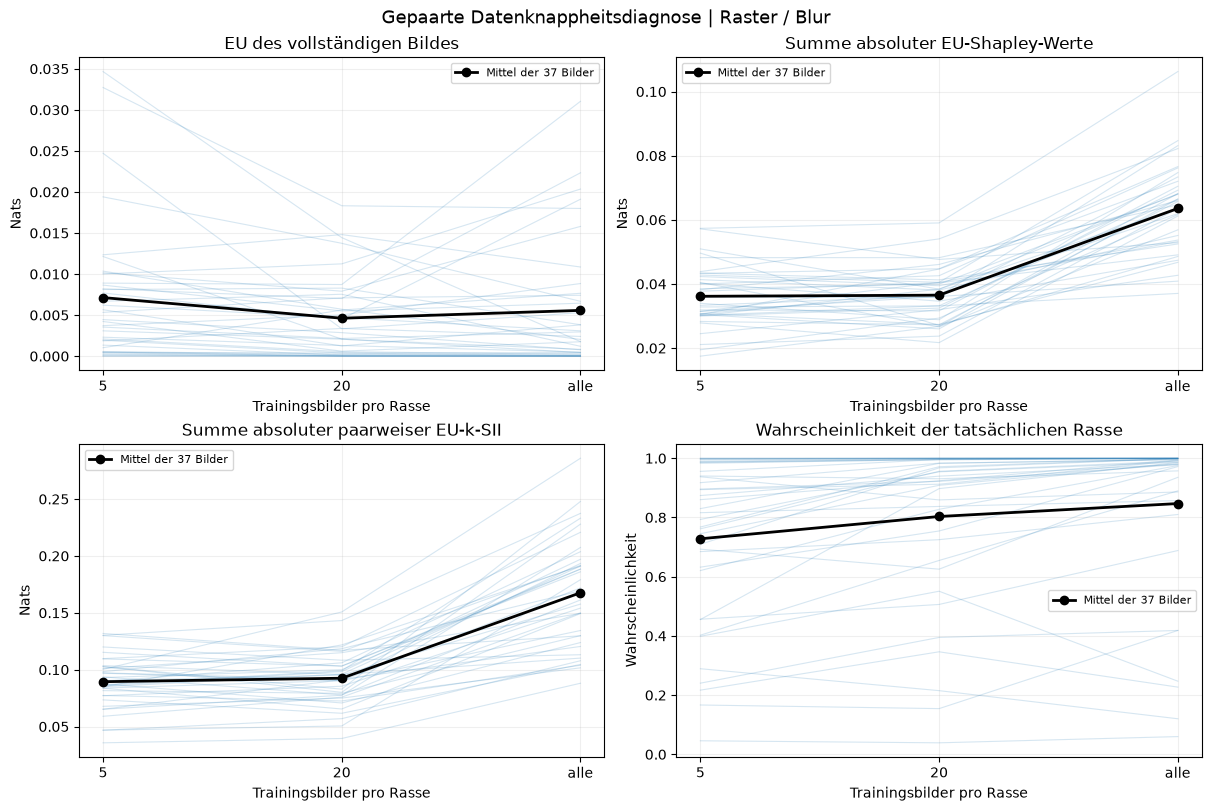

| Daten pro Rasse | EU: Kohortenmittel je Teilmenge | EU-Kartenabstand zum Vollmodell |
| :--- | :--- | :--- |
| 5 | 0.0070372, 0.0079136, 0.0064481 | 0.046205, 0.048827, 0.051533 |
| 20 | 0.003864, 0.0054441, 0.0045544 | 0.044076, 0.044319, 0.043734 |
| all | 0.005576 | 0 |

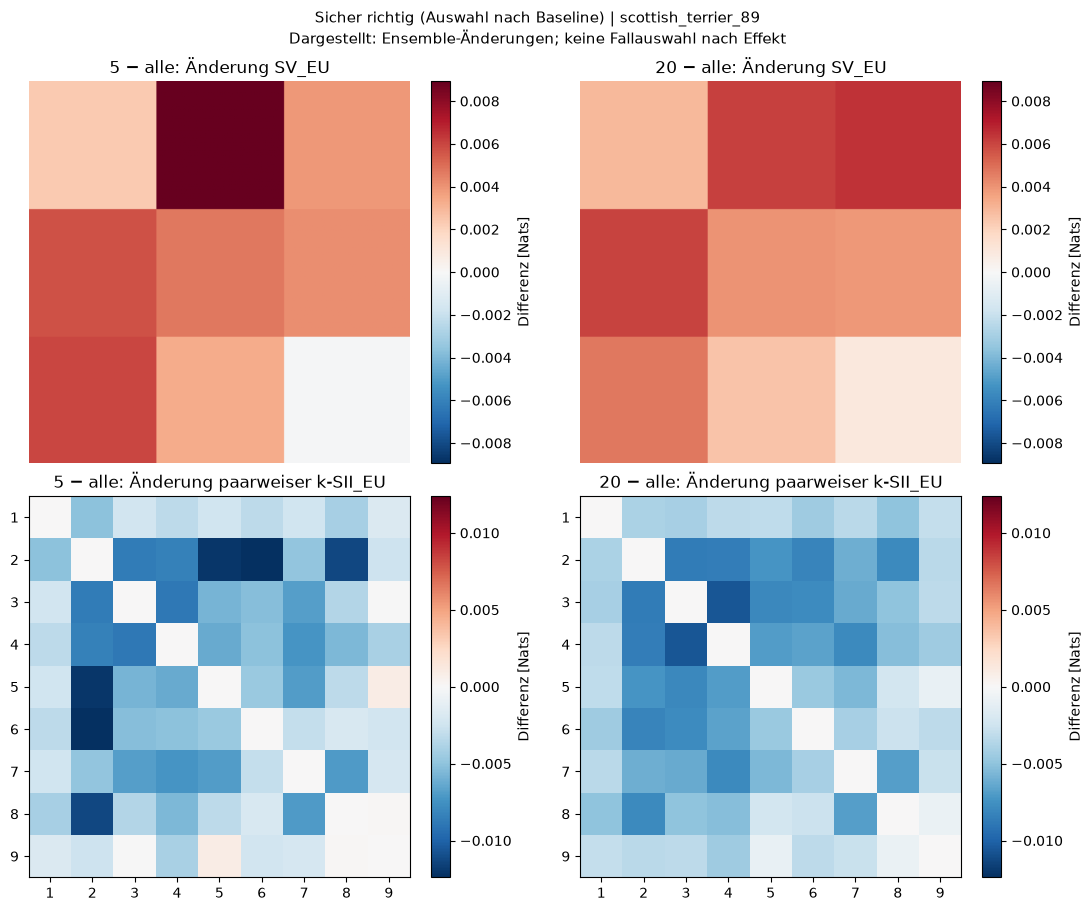

In [7]:
cohort_order = list(shapiq_index["cohort_ids"])
scarcity_summary = {}
for level in (5, 20, "all"):
    names = ["full"] if level == "all" else [f"k{level}_s{seed}" for seed in (10, 11, 12)]
    values = {metric: [] for metric in ("EU", "sv_mass", "pair_mass", "map_l1", "true_P")}
    for name in names:
        per_model = {metric: [] for metric in values}
        for image_id in cohort_order:
            key = (image_id, "grid", "blur")
            full = full_results[key]
            result = full if name == "full" else scarce_results[(key, name)]
            eu = result["games"]["EU"]
            per_model["EU"].append(eu["values"][-1].item())
            per_model["sv_mass"].append(eu["sv"].abs().sum().item())
            per_model["pair_mass"].append(torch.triu(eu["ksii_pairs"].abs(), diagonal=1).sum().item())
            per_model["map_l1"].append((eu["sv"] - full["games"]["EU"]["sv"]).abs().sum().item())
            per_model["true_P"].append(result["probabilities"][-1, result["true_class"]].item())
        for metric in values:
            values[metric].append(per_model[metric])
    scarcity_summary[level] = {metric: np.asarray(entries) for metric, entries in values.items()}

levels = (5, 20, "all")
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, metric, title in zip(axes.flat, ("EU", "sv_mass", "pair_mass", "true_P"),
                            ("EU des vollständigen Bildes", "Summe absoluter EU-Shapley-Werte",
                             "Summe absoluter paarweiser EU-k-SII", "Wahrscheinlichkeit der tatsächlichen Rasse"), strict=True):
    means = np.stack([scarcity_summary[level][metric].mean(axis=0) for level in levels], axis=1)
    for image_values in means:
        ax.plot(range(3), image_values, color="C0", alpha=0.18, linewidth=0.8)
    ax.plot(range(3), means.mean(axis=0), color="black", marker="o", linewidth=2, label="Mittel der 37 Bilder")
    ax.set(xticks=range(3), xticklabels=("5", "20", "alle"), xlabel="Trainingsbilder pro Rasse", title=title,
           ylabel="Wahrscheinlichkeit" if metric == "true_P" else "Nats")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Gepaarte Datenknappheitsdiagnose | Raster / Blur", fontsize=13)
plt.show()

rows = ["| Daten pro Rasse | EU: Kohortenmittel je Teilmenge | EU-Kartenabstand zum Vollmodell |",
        "| :--- | :--- | :--- |"]
for level in levels:
    mean_eu = scarcity_summary[level]["EU"].mean(axis=1)
    map_l1 = scarcity_summary[level]["map_l1"].mean(axis=1)
    rows.append(f"| {level} | {', '.join(f'{value:.5g}' for value in mean_eu)} | {', '.join(f'{value:.5g}' for value in map_l1)} |")
display(Markdown("\n".join(rows)))

# Signed EU-map differences use the same image and fixed target/coalitions.
case = diagnostics[0]
key = (case["image_id"], "grid", "blur")
record = record_lookup[key]
source = load_torch(ARTIFACT_DIR / record["path"])
full = full_results[key] if key in full_results else combined_result(record)
comparisons = {}
for level in (5, 20):
    samples = []
    for seed in (10, 11, 12):
        name = f"k{level}_s{seed}"
        samples.append(scarce_results[(key, name)] if (key, name) in scarce_results else combined_result(record, name))
    comparisons[level] = samples
map_changes = [np.mean([item["games"]["EU"]["sv"].numpy() for item in comparisons[level]], axis=0)
               - full["games"]["EU"]["sv"].numpy() for level in (5, 20)]
pair_changes = [np.mean([item["games"]["EU"]["ksii_pairs"].numpy() for item in comparisons[level]], axis=0)
                - full["games"]["EU"]["ksii_pairs"].numpy() for level in (5, 20)]
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
for column, level in enumerate((5, 20)):
    shown = axes[0, column].imshow(map_changes[column][source["regions"].numpy()], cmap="RdBu_r",
                                  norm=signed_norm(np.concatenate(map_changes)))
    axes[0, column].set_title(f"{level} − alle: Änderung SV_EU")
    axes[0, column].axis("off")
    fig.colorbar(shown, ax=axes[0, column], label="Differenz [Nats]")
    shown = axes[1, column].imshow(pair_changes[column], cmap="RdBu_r", norm=signed_norm(np.stack(pair_changes)))
    axes[1, column].set(title=f"{level} − alle: Änderung paarweiser k-SII_EU", xticks=np.arange(9), yticks=np.arange(9),
                       xticklabels=np.arange(1, 10), yticklabels=np.arange(1, 10))
    fig.colorbar(shown, ax=axes[1, column], label="Differenz [Nats]")
fig.suptitle(
    f"{case['role']} (Auswahl nach Baseline) | {case['image_id']}\n"
    "Dargestellt: Ensemble-Änderungen; keine Fallauswahl nach Effekt", fontsize=11,
)
plt.show()

## 7. Gezielte Verdeckung mit vollständiger Zufallskontrolle

- Wir entfernen jeweils **k = 1, 2, 3 Rasterregionen**. Die Reihenfolgen entstehen aus
  den größten P-SV, den größten/kleinsten **signierten EU-SV** oder dem
  Tier-/Hintergrundanteil der Trimaps. Auch der größte EU-SV kann negativ sein;
  die Strategie wählt trotzdem fest k Regionen. Sie behauptet keinen positiven Beitrag,
  wenn es im jeweiligen Spiel keinen gibt. Positive EU-SV werden pro Bild gezählt.
- Für jedes k liegen bereits alle `C(9,k)` möglichen Verdeckungen in der Tabelle.
  Ihr exakter Mittelwert ist die Zufallskontrolle; die Hülle zeigt das gemittelte Minimum/Maximum
  je Bild. Sie ist **kein Konfidenzintervall**.
- Die Rasterfelder unterscheiden sich wegen 224/3 geringfügig in Fläche. Verglichen wird dieselbe
  Anzahl Regionen; die tatsächlichen verdeckten Flächen werden zusätzlich angegeben.
- P zeigt die Änderung der festgehaltenen Baseline-Zielwahrscheinlichkeit. Positive Änderungen
  von TU/AU/EU bedeuten mehr Unsicherheit; eine monotone Reaktion wird nicht vorausgesetzt.
- Diese Prüfung verwendet dasselbe Maskierungsspiel wie die Erklärung. Sie misst interne
  Konsistenz, keine unabhängige Erklärungsqualität und keine kausalen Effekte natürlicher Bilder.

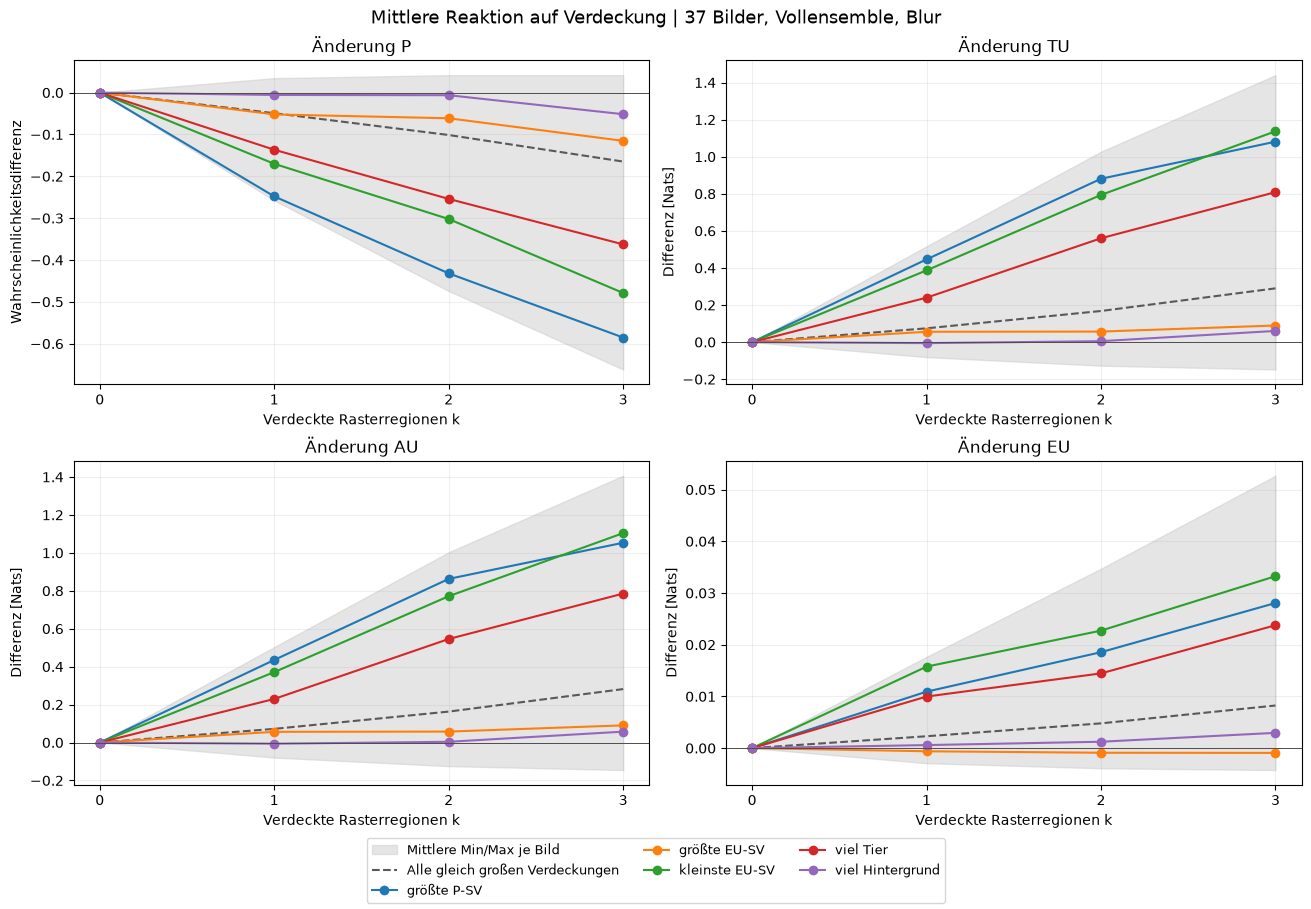

| Auswahl | Mittlerer verdeckter Flächenanteil: k=1 / 2 / 3 |
| :--- | :--- |
| größte P-SV | 11.2% / 22.3% / 33.4% |
| größte EU-SV | 11.1% / 22.2% / 33.3% |
| kleinste EU-SV | 11.2% / 22.3% / 33.4% |
| viel Tier | 11.2% / 22.3% / 33.4% |
| viel Hintergrund | 11.1% / 22.3% / 33.3% |

**Vorzeichen der neun EU-Beiträge:**

| Positive EU-SV pro Bild (> 1e−10 Nats) | Bilder |
| ---: | ---: |
| 0 | 5 |
| 1 | 14 |
| 2 | 6 |
| 3 | 8 |
| 4 | 1 |
| 5 | 2 |
| 6 | 1 |

Bilder ohne positiven EU-SV: 5 / 37


In [8]:
STRATEGIES = ("größte P-SV", "größte EU-SV", "kleinste EU-SV", "viel Tier", "viel Hintergrund")
deletion = {score: {strategy: [] for strategy in (*STRATEGIES, "Zufall", "Minimum", "Maximum")}
            for score in SCORES}
deleted_area = {strategy: [] for strategy in STRATEGIES}
deletion_details = []
for image_id in cohort_order:
    key = (image_id, "grid", "blur")
    source = load_torch(ARTIFACT_DIR / record_lookup[key]["path"])
    result = full_results[key]
    coalitions = source["coalitions"].numpy()
    areas, fractions, _ = geometry(source)
    ranking = {
        "größte P-SV": np.argsort(-result["games"]["P"]["sv"].numpy(), kind="stable"),
        "größte EU-SV": np.argsort(-result["games"]["EU"]["sv"].numpy(), kind="stable"),
        "kleinste EU-SV": np.argsort(result["games"]["EU"]["sv"].numpy(), kind="stable"),
        "viel Tier": np.argsort(-fractions[:, 0], kind="stable"),
        "viel Hintergrund": np.argsort(-fractions[:, 1], kind="stable"),
    }
    remaining_counts = coalitions.sum(axis=1)
    for strategy in STRATEGIES:
        deleted_area[strategy].append([0.0, *[areas[ranking[strategy][:k]].sum() for k in (1, 2, 3)]])
    detail = {
        "image_id": image_id,
        "true_class": result["true_class"],
        "positive_eu_sv_regions": int((result["games"]["EU"]["sv"] > 1e-10).sum()),
        "indices": {},
    }
    for score in SCORES:
        table = result["games"][score]["values"].numpy()
        original = table[-1]
        for strategy in STRATEGIES:
            selected_rows = [len(table) - 1]
            for k in (1, 2, 3):
                keep = np.ones(9, dtype=np.int64)
                keep[ranking[strategy][:k]] = 0
                selected_rows.append(int(keep @ (1 << np.arange(9))))
            deletion[score][strategy].append(table[selected_rows] - original)
            detail["indices"][strategy] = selected_rows
        controls = [table[remaining_counts == 9 - k] - original for k in (0, 1, 2, 3)]
        for name, reducer in (("Zufall", np.mean), ("Minimum", np.min), ("Maximum", np.max)):
            deletion[score][name].append([reducer(values) for values in controls])
    deletion_details.append(detail)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for ax, score in zip(axes.flat, SCORES, strict=True):
    mean_control = np.mean(deletion[score]["Zufall"], axis=0)
    low = np.mean(deletion[score]["Minimum"], axis=0)
    high = np.mean(deletion[score]["Maximum"], axis=0)
    ax.fill_between(range(4), low, high, color="0.8", alpha=0.5, label="Mittlere Min/Max je Bild")
    ax.plot(range(4), mean_control, color="0.35", linestyle="--", label="Alle gleich großen Verdeckungen")
    for index, strategy in enumerate(STRATEGIES):
        ax.plot(range(4), np.mean(deletion[score][strategy], axis=0), marker="o", label=strategy, color=f"C{index}")
    ax.axhline(0, color="0.3", linewidth=0.7)
    ax.set(xticks=range(4), xlabel="Verdeckte Rasterregionen k", title=f"Änderung {score}",
           ylabel="Wahrscheinlichkeitsdifferenz" if score == "P" else "Differenz [Nats]")
    ax.grid(alpha=0.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3, fontsize=9)
fig.suptitle("Mittlere Reaktion auf Verdeckung | 37 Bilder, Vollensemble, Blur", fontsize=13)
plt.show()

area_rows = ["| Auswahl | Mittlerer verdeckter Flächenanteil: k=1 / 2 / 3 |",
             "| :--- | :--- |"]
for strategy in STRATEGIES:
    means = np.mean(deleted_area[strategy], axis=0)[1:]
    area_rows.append(f"| {strategy} | {' / '.join(f'{value:.1%}' for value in means)} |")
display(Markdown("\n".join(area_rows)))
positive_counts = [detail["positive_eu_sv_regions"] for detail in deletion_details]
count_rows = ["| Positive EU-SV pro Bild (> 1e−10 Nats) | Bilder |", "| ---: | ---: |"]
for count in sorted(set(positive_counts)):
    count_rows.append(f"| {count} | {positive_counts.count(count)} |")
display(Markdown("**Vorzeichen der neun EU-Beiträge:**\n\n" + "\n".join(count_rows)))
print("Bilder ohne positiven EU-SV:", positive_counts.count(0), "/ 37")

## 8. Negative Befunde sichtbar halten

- Niedrige EU bedeutet Übereinstimmung dieser Köpfe, nicht automatisch eine richtige Vorhersage.
  Wir zeigen auch Fehler mit der jeweils kleinsten EU und nennen ihre tatsächliche Konfidenz.
- Der Grenzwert für „niedrige EU“ ist das untere Quartil der Vollensemble-EU auf dem
  unveränderten Validierungssplit. „Hohe Konfidenz“ bedeutet vorab festgelegte 90 %.
- Die Verdeckungsfälle beziehen sich auf zwei tierhaltige Rasterfelder. Sie sind künstliche
  Eingriffe; die ursprüngliche Rasse bleibt eine Referenz für die Reaktion, kein neues annotiertes
  Label des veränderten Bildes.
- Auch **keine** gefundenen sicheren Fehler oder **keine** zusätzliche EU bei Datenknappheit
  sind berichtenswerte Ergebnisse. Wir suchen keine Fälle nach, bis eine gewünschte Geschichte entsteht.

**Validierungsgrenze niedrige EU:** 0.000105017 Nats.

- **Vollbild:** 6/37 Abweichungen von der ursprünglichen Rasse; davon 0 mit Konfidenz ≥ 90 % und niedriger EU.
- **2 Tier-Patches verdeckt:** 9/37 Abweichungen von der ursprünglichen Rasse; davon 0 mit Konfidenz ≥ 90 % und niedriger EU.

Gezielt sortierte Fehlerbeispiele nach kleinster EU; keine Häufigkeitsstichprobe.

| Bild / Eingriff | Ursprüngliche Rasse | Vorhersage | Konfidenz | EU [Nats] |
| :--- | :--- | :--- | ---: | ---: |
| staffordshire_bull_terrier_33 / 2 Tier-Patches verdeckt | Staffordshire Bull Terrier | American Bulldog | 47.8% | 0.0139403 |
| Abyssinian_79 / Vollbild | Abyssinian | Siamese | 46.7% | 0.0158025 |
| Sphynx_30 / Vollbild | Sphynx | Abyssinian | 72.4% | 0.0179903 |
| american_pit_bull_terrier_42 / Vollbild | American Pit Bull Terrier | Staffordshire Bull Terrier | 68.5% | 0.0191141 |
| american_bulldog_208 / Vollbild | American Bulldog | Boxer | 55.2% | 0.0203514 |
| american_pit_bull_terrier_42 / 2 Tier-Patches verdeckt | American Pit Bull Terrier | German Shorthaired | 56.5% | 0.0220858 |

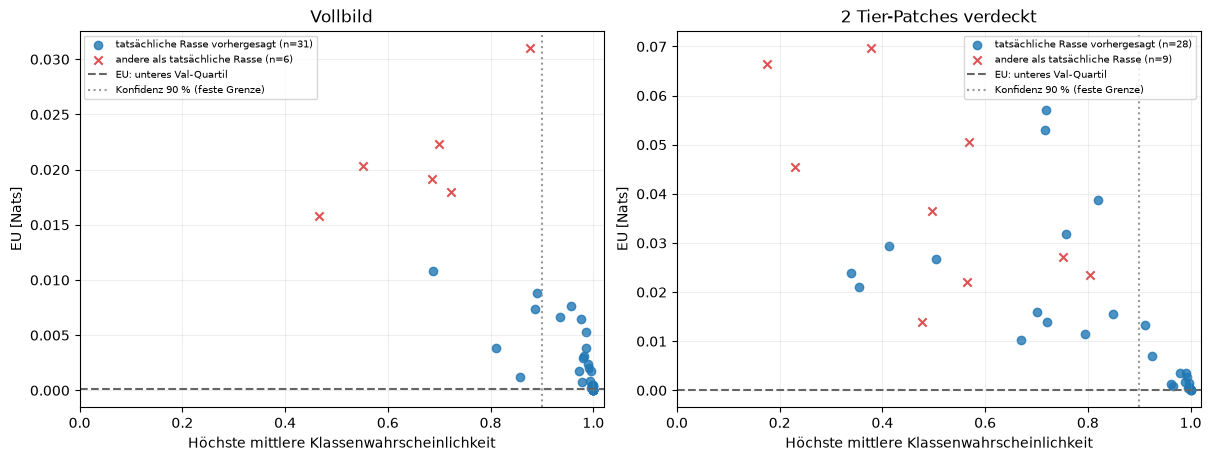

In [9]:
validation_features = bundle["trainval"]["features"][bundle["val_indices"]]
validation_eu = probly_scores(ensembles["full"], validation_features, target_class=0)["scores"]["EU"].numpy()
low_eu_threshold = float(np.quantile(validation_eu, 0.25))
failure_rows = []
all_observations = []
for detail in deletion_details:
    key = (detail["image_id"], "grid", "blur")
    result = full_results[key]
    for condition, index in (("Vollbild", len(result["probabilities"]) - 1),
                             ("2 Tier-Patches verdeckt", detail["indices"]["viel Tier"][2])):
        probabilities = result["probabilities"][index]
        confidence, prediction = probabilities.max(0)
        eu = result["games"]["EU"]["values"][index].item()
        row = {
            "image_id": detail["image_id"], "condition": condition, "true_class": detail["true_class"],
            "prediction": int(prediction), "confidence": float(confidence), "EU": eu,
            "reference_mismatch": int(prediction) != detail["true_class"],
            "low_eu": eu <= low_eu_threshold,
        }
        all_observations.append(row)
        if row["reference_mismatch"]:
            failure_rows.append(row)

display(Markdown(f"**Validierungsgrenze niedrige EU:** {low_eu_threshold:.6g} Nats."))
summary_lines = []
for condition in ("Vollbild", "2 Tier-Patches verdeckt"):
    subset = [row for row in all_observations if row["condition"] == condition]
    mismatch = sum(row["reference_mismatch"] for row in subset)
    low_and_confident = sum(row["reference_mismatch"] and row["low_eu"] and row["confidence"] >= 0.9 for row in subset)
    summary_lines.append(f"- **{condition}:** {mismatch}/37 Abweichungen von der ursprünglichen Rasse; "
                         f"davon {low_and_confident} mit Konfidenz ≥ 90 % und niedriger EU.")
display(Markdown("\n".join(summary_lines)))

table = ["| Bild / Eingriff | Ursprüngliche Rasse | Vorhersage | Konfidenz | EU [Nats] |",
         "| :--- | :--- | :--- | ---: | ---: |"]
for row in sorted(failure_rows, key=lambda row: (row["EU"], row["image_id"]))[:6]:
    table.append(f"| {row['image_id']} / {row['condition']} | {class_names[row['true_class']]} | "
                 f"{class_names[row['prediction']]} | {row['confidence']:.1%} | {row['EU']:.6g} |")
if failure_rows:
    display(Markdown("Gezielt sortierte Fehlerbeispiele nach kleinster EU; keine Häufigkeitsstichprobe.\n\n" + "\n".join(table)))
else:
    display(Markdown("In dieser festgelegten Kohorte wurden unter diesen beiden Bedingungen keine Abweichungen beobachtet."))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, condition in zip(axes, ("Vollbild", "2 Tier-Patches verdeckt"), strict=True):
    for mismatch, label, marker, color in ((False, "tatsächliche Rasse vorhergesagt", "o", "C0"),
                                           (True, "andere als tatsächliche Rasse", "x", "C3")):
        rows = [row for row in all_observations if row["condition"] == condition and row["reference_mismatch"] == mismatch]
        ax.scatter([row["confidence"] for row in rows], [row["EU"] for row in rows],
                   marker=marker, color=color, label=f"{label} (n={len(rows)})", alpha=0.8)
    ax.axhline(low_eu_threshold, color="0.4", linestyle="--", label="EU: unteres Val-Quartil")
    ax.axvline(0.9, color="0.6", linestyle=":", label="Konfidenz 90 % (feste Grenze)")
    ax.set(title=condition, xlabel="Höchste mittlere Klassenwahrscheinlichkeit", ylabel="EU [Nats]", xlim=(0, 1.02))
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)
plt.show()

## 9. Befunde festhalten, ohne Identitäten als Entdeckungen auszugeben

- Die nachstehenden Zahlen entstehen aus der festen Kohorte und den gespeicherten Modellen.
  Sie werden auch dann ausgegeben, wenn die erwartete Richtung ausbleibt.
- Ein größerer EU-Wert bei Datenknappheit ist eine Reaktion des Kopfensembles; fehlender Anstieg
  kann eine Grenze des gemeinsamen Backbones oder der kleinen Ensemblegröße zeigen.
- Attributionsmasse auf dem Tier, konsistente Verdeckung und Referenzstabilität beantworten
  unterschiedliche Fragen. Keiner dieser Tests ersetzt eine unabhängige Ground Truth für Erklärungen.
- Artefakte enthalten Modell- und Quellfingerprints. Ein geänderter Kopf invalidiert nur die
  günstige Spielauswertung; die passenden VGG-Koalitionsmerkmale bleiben wiederverwendbar.

In [10]:
# Read existing derived tables: no new model or image evaluations.
def finite_median(values) -> float | None:
    """Summarize defined cases while retaining missing-result semantics."""
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]
    return float(np.median(valid)) if len(valid) else None


ranked_change = np.asarray(deletion["EU"]["kleinste EU-SV"])[:, 3]
control_change = np.asarray(deletion["EU"]["Zufall"])[:, 3]
central_diagnostics = {
    "deletion_k": 3,
    "deletion_strategy": "kleinste signierte EU-SV",
    "mean_ranked_EU_change": float(ranked_change.mean()),
    "mean_all_subsets_EU_change": float(control_change.mean()),
    "mean_paired_EU_difference": float((ranked_change - control_change).mean()),
    "median_EU_mass_excess_over_area": {
        kind: [finite_median(np.asarray(localization[kind]["EU"])[:, group]) for group in range(3)]
        for kind in ("grid", "semantic")
    },
    "median_reference_rho": {
        score: finite_median(reference_sensitivity[score]["rho"]) for score in ("P", "EU")
    },
}

summary = {
    "schema_version": 1,
    "baseline_fingerprint": baseline_fingerprint,
    "model_fingerprints": model_fingerprints,
    "cohort_ids": shapiq_index["cohort_ids"],
    "low_eu_validation_threshold": low_eu_threshold,
    "reference_sensitivity": {
        score: {field: [float(value) if np.isfinite(value) else None for value in values]
                for field, values in fields.items()}
        for score, fields in reference_sensitivity.items()
    },
    "scarcity_cohort_mean_EU": {
        str(level): scarcity_summary[level]["EU"].mean(axis=1).tolist() for level in levels
    },
    "negative_case_observations": all_observations,
    "positive_eu_sv_regions_by_image": [
        {"image_id": detail["image_id"], "count": detail["positive_eu_sv_regions"]}
        for detail in deletion_details
    ],
    "central_diagnostics": central_diagnostics,
    "scope": "descriptive, 37 fixed images; head-only ensembles; masked interventions",
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
full_mean = float(scarcity_summary["all"]["EU"].mean())
findings = [
    f"- **Verdeckung / interne Konsistenz:** Bei drei Regionen mit den kleinsten signierten EU-SV "
    f"ändert sich EU im Mittel um {central_diagnostics['mean_ranked_EU_change']:+.5g} Nats; "
    f"über alle gleich großen Verdeckungen um {central_diagnostics['mean_all_subsets_EU_change']:+.5g}. "
    f"Die gepaarte Differenz beträgt {central_diagnostics['mean_paired_EU_difference']:+.5g}. "
    "Das vergleicht Eingriffe derselben Spieltabelle und ist keine unabhängige Validierung."
]
for kind, name in (("grid", "Raster"), ("semantic", "Semantisches Spiel")):
    foreground, background, _ = central_diagnostics["median_EU_mass_excess_over_area"][kind]
    if foreground is not None and background is not None:
        findings.append(
            f"- **{name} / EU-Lokalisierung:** Median der absoluten SV-Masse minus Flächenanteil: "
            f"Tier {100 * foreground:+.1f}, Hintergrund {100 * background:+.1f} Prozentpunkte. "
            "Positive Werte bedeuten überproportionale Beitragsmasse; sie bewerten keine kausale Richtigkeit."
        )
p_rho = central_diagnostics["median_reference_rho"]["P"]
eu_rho = central_diagnostics["median_reference_rho"]["EU"]
if p_rho is not None and eu_rho is not None:
    relation = "geringer" if eu_rho < p_rho else "höher" if eu_rho > p_rho else "gleich"
    findings.append(
        f"- **EU gegen P / Referenzwechsel:** Medianes Rang-ρ {eu_rho:.3f} für EU und {p_rho:.3f} für P. "
        f"Die Rangstabilität der EU-Beiträge ist hier {relation}; räumliche Unsicherheitsaussagen "
        "hängen deshalb zusätzlich vom gewählten Ersatzbild ab."
    )
for level in (5, 20):
    scarce_mean = float(scarcity_summary[level]["EU"].mean())
    findings.append(f"- **{level} Bilder/Rasse:** mittlere Vollbild-EU {scarce_mean:.5g} Nats; "
                    f"Vollensemble {full_mean:.5g}; Differenz {scarce_mean - full_mean:+.5g}.")
for score in SCORES:
    values = np.asarray(reference_sensitivity[score]["rho"])
    valid = values[np.isfinite(values)]
    if len(valid):
        findings.append(f"- **Referenzstabilität {score}:** medianes Spearman-ρ {np.median(valid):.3f} "
                        f"über {len(valid)}/37 definierte Kartenpaare.")
display(Markdown("\n".join(findings)))
print("Ergebnisse gespeichert:", OUTPUT_DIR / "summary.json")

- **Verdeckung / interne Konsistenz:** Bei drei Regionen mit den kleinsten signierten EU-SV ändert sich EU im Mittel um +0.033253 Nats; über alle gleich großen Verdeckungen um +0.0082422. Die gepaarte Differenz beträgt +0.025011. Das vergleicht Eingriffe derselben Spieltabelle und ist keine unabhängige Validierung.
- **Raster / EU-Lokalisierung:** Median der absoluten SV-Masse minus Flächenanteil: Tier +10.2, Hintergrund -11.1 Prozentpunkte. Positive Werte bedeuten überproportionale Beitragsmasse; sie bewerten keine kausale Richtigkeit.
- **Semantisches Spiel / EU-Lokalisierung:** Median der absoluten SV-Masse minus Flächenanteil: Tier +31.3, Hintergrund -23.3 Prozentpunkte. Positive Werte bedeuten überproportionale Beitragsmasse; sie bewerten keine kausale Richtigkeit.
- **EU gegen P / Referenzwechsel:** Medianes Rang-ρ 0.633 für EU und 0.883 für P. Die Rangstabilität der EU-Beiträge ist hier geringer; räumliche Unsicherheitsaussagen hängen deshalb zusätzlich vom gewählten Ersatzbild ab.
- **5 Bilder/Rasse:** mittlere Vollbild-EU 0.007133 Nats; Vollensemble 0.005576; Differenz +0.001557.
- **20 Bilder/Rasse:** mittlere Vollbild-EU 0.0046208 Nats; Vollensemble 0.005576; Differenz -0.00095515.
- **Referenzstabilität P:** medianes Spearman-ρ 0.883 über 37/37 definierte Kartenpaare.
- **Referenzstabilität TU:** medianes Spearman-ρ 0.817 über 37/37 definierte Kartenpaare.
- **Referenzstabilität AU:** medianes Spearman-ρ 0.817 über 37/37 definierte Kartenpaare.
- **Referenzstabilität EU:** medianes Spearman-ρ 0.633 über 37/37 definierte Kartenpaare.

Ergebnisse gespeichert: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/combined/summary.json


### Quellen und Anschluss

- [probly: gemeinsame Pipeline](https://pwhofman.github.io/probly/latest/guide/core_pillars.html)
- [probly: Second-Order-Methoden](https://pwhofman.github.io/probly/latest/guide/methods/second_order.html)
- [shapiq: ExactComputer](https://shapiq.readthedocs.io/en/latest/api/shapiq.game_theory.exact.html)
- [Oxford-IIIT Pet: Annotationen und Originalarbeit](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Weitere Modellfamilien oder unabhängige CNN-Backbones wären ein neuer Versuch. Diese Reihe
isoliert bewusst die Unsicherheit kleiner Köpfe auf denselben VGG-Merkmalen. Neue
Kalibrierungs- oder Conformal-Experimente benötigen einen eigenen Kalibrierungssplit;
der hier ausgewertete Testsplit darf dafür nicht nachträglich zum Fitten dienen.